# Kode 1.1

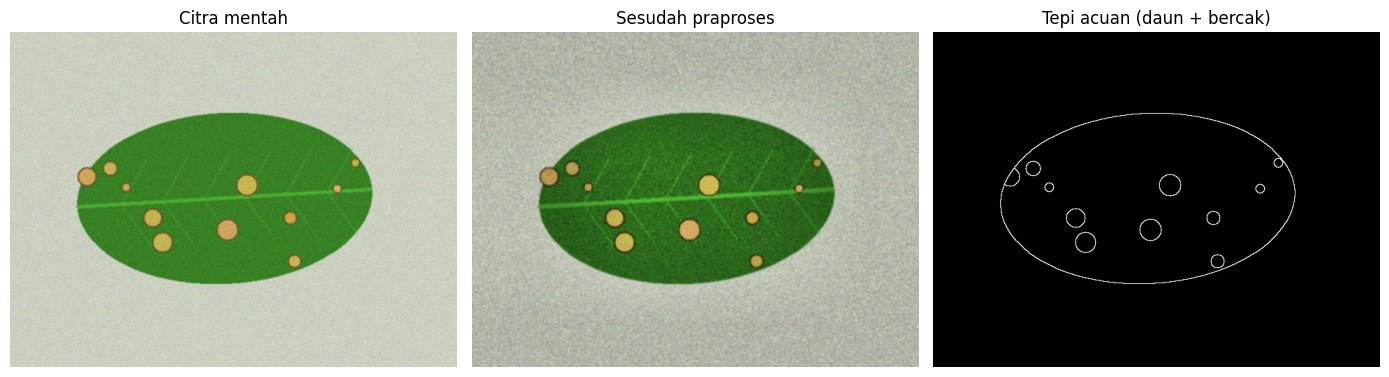

In [4]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])


# Kode 1.2

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 591.7


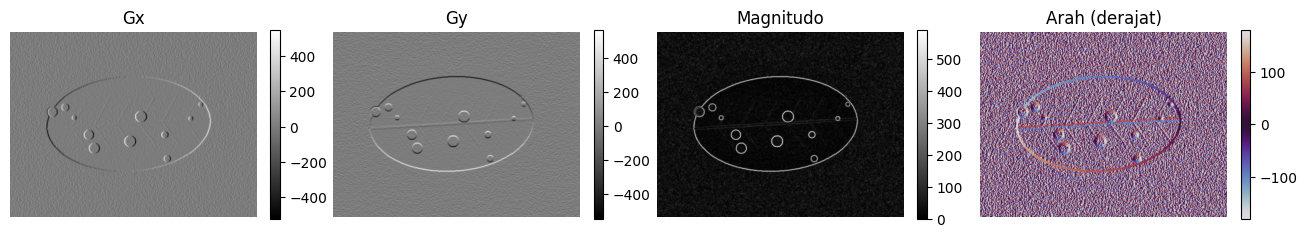

In [5]:
g = pra[:, :, 2].astype(np.float32)                   # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)                  # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)                  # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)


# Kode 1.3

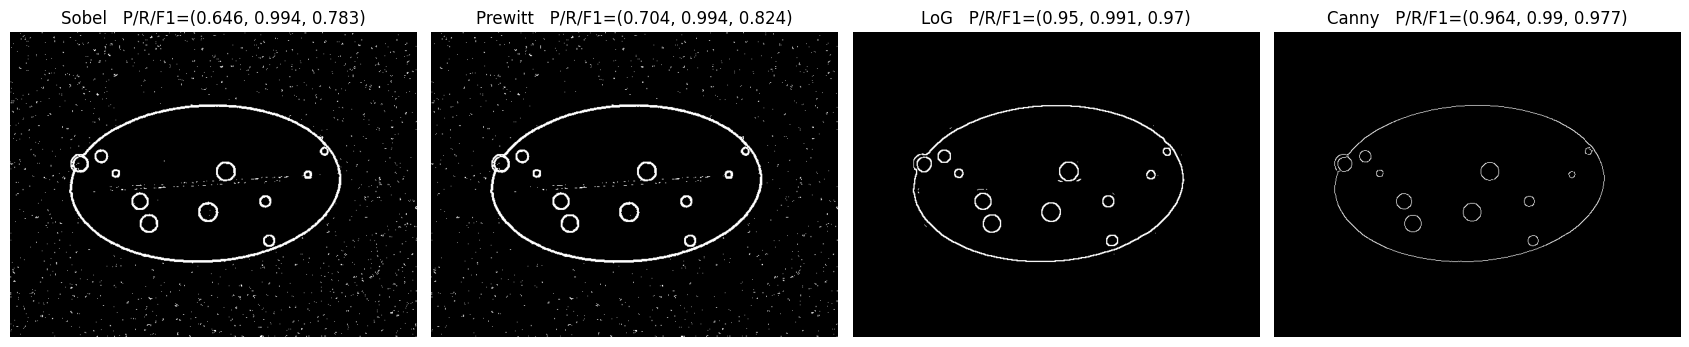

In [6]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
                      cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) *
            255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log,
          "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}   P/R/F1={skor_tepi(e, acuan)}" for nm, e
       in hasil.items()],
       ukuran=(17, 3.6))


# Kode 1.4

In [7]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R",
                          im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal",
                                          "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R",
                                                             "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)


                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.762  0.748  0.754
                LoG      0.617  0.997  0.755
                Prewitt  0.794  0.954  0.856
                Sobel    0.757  0.962  0.835
          R     Canny    0.984  0.979  0.981
                LoG      0.887  0.997  0.929
                Prewitt  0.522  0.996  0.634
                Sobel    0.459  0.996  0.572
praproses Gray  Canny    0.712  0.945  0.804
                LoG      0.551  0.996  0.699
                Prewitt  0.580  0.996  0.725
                Sobel    0.544  0.996  0.693
          R     Canny    0.957  0.987  0.971
                LoG      0.812  0.997  0.883
                Prewitt  0.451  0.997  0.583
                Sobel    0.405  0.997  0.537


# Kode 1.5

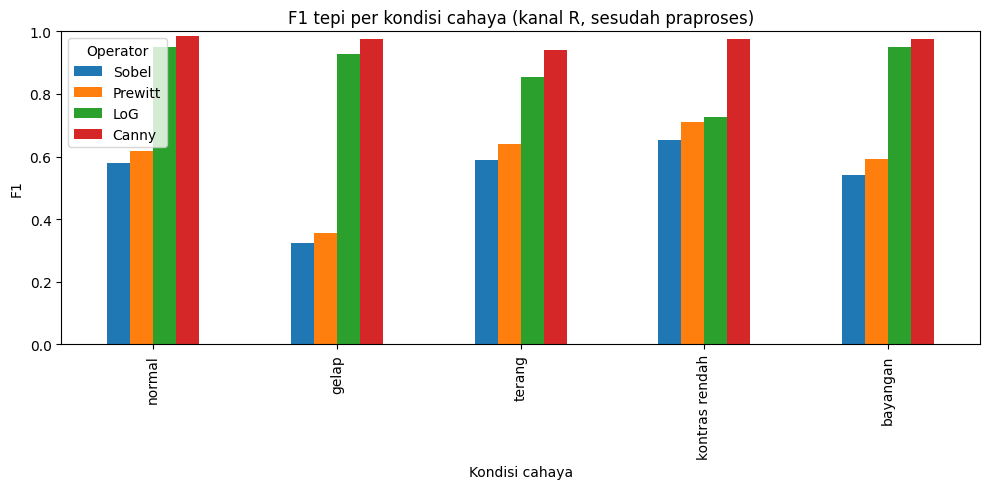

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
normal          0.580    0.617  0.951  0.986
gelap           0.324    0.357  0.929  0.975
terang          0.590    0.640  0.854  0.940
kontras rendah  0.653    0.709  0.728  0.976
bayangan        0.541    0.592  0.950  0.976


In [8]:
pil = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
pivot = pil.groupby(["kondisi", "metode"])["F1"].mean().unstack()
pivot = pivot[["Sobel", "Prewitt", "LoG", "Canny"]]
urutan = [k for k in tabel_tepi.kondisi.unique() if k in pivot.index]
pivot = pivot.reindex(urutan)
pivot.index = pivot.index.str.replace("_", " ")

ax = pivot.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
ax.set_title("F1 tepi per kondisi cahaya (kanal R, sesudah praproses)")
ax.set_xlabel("Kondisi cahaya")
ax.set_ylabel("F1")
ax.legend(title="Operator")
plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150)
plt.show()
print(pivot.round(3))


# Kode 2.1

In [9]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]          # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1",
                                     "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1",
                                          "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas",
                        values="R_bercak").round(3))


                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.519  0.993  0.622     0.968
      30/90    0.020  0.996  0.040     0.981
      50/150   0.129  0.994  0.185     0.973
1.0   100/200  0.971  0.991  0.981     0.957
      30/90    0.219  0.993  0.310     0.963
      50/150   0.858  0.992  0.906     0.960
2.0   100/200  0.814  0.781  0.787     0.672
      30/90    0.957  0.987  0.971     0.941
      50/150   0.979  0.973  0.976     0.821
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.969   0.967
      30/90    0.988   0.975
      50/150   0.977   0.969
1.0   100/200  0.964   0.949
      30/90    0.972   0.953
      50/150   0.969   0.952
2.0   100/200  0.720   0.624
      30/90    0.942   0.940
      50/150   0.890   0.752


# Kode 2.2

In [10]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x
median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
                     pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis",
                      skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90",
                      skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1",
                                    "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi",
                       values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))


kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.547  0.517           0.838   0.766   0.882
      tetap 30/90     0.749  0.788           0.951   0.759   0.774
R     otomatis        0.369  0.342           0.822   0.831   0.953
      tetap 30/90     0.976  0.975           0.976   0.986   0.940
kanal  kondisi       
Gray   bayangan          120.5
       gelap             132.0
       kontras_rendah    150.5
       normal            170.4
       terang            193.8
R      bayangan          127.2
       gelap             152.2
       kontras_rendah    153.4
       normal            177.5
       terang            198.0
Name: median, dtype: float64


# Langkah 2.4



In [11]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """Ambang dari persentil magnitudo: atas = persentil ke-q, bawah = rasio x atas."""
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    gf = g.astype(np.float32)
    mag = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))
    hi = np.percentile(mag, q)
    lo = rasio * hi
    return cv2.Canny(g, int(lo), int(hi))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
                     pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            baris.append([d.kondisi_cahaya, kanal, f"q{q}",
                          skor_tepi(canny_persentil(g, q), ac)[2]])
pers = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1"])
print(pers.pivot_table(index=["kanal", "ambang"], columns="kondisi",
                       values="F1").round(3))


kondisi       bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                 
Gray  q90        0.065  0.063           0.056   0.064   0.058
      q95        0.262  0.288           0.142   0.343   0.249
      q98        0.746  0.783           0.736   0.766   0.738
R     q90        0.070  0.064           0.058   0.067   0.062
      q95        0.221  0.136           0.119   0.229   0.212
      q98        0.968  0.984           0.888   0.987   0.918


# Kode 2.3

kanal            Gray      R
kondisi                     
bayangan        901.0    0.0
gelap           571.8    0.0
kontras_rendah   39.0    0.0
normal          870.0  168.8
terang          907.8  348.0


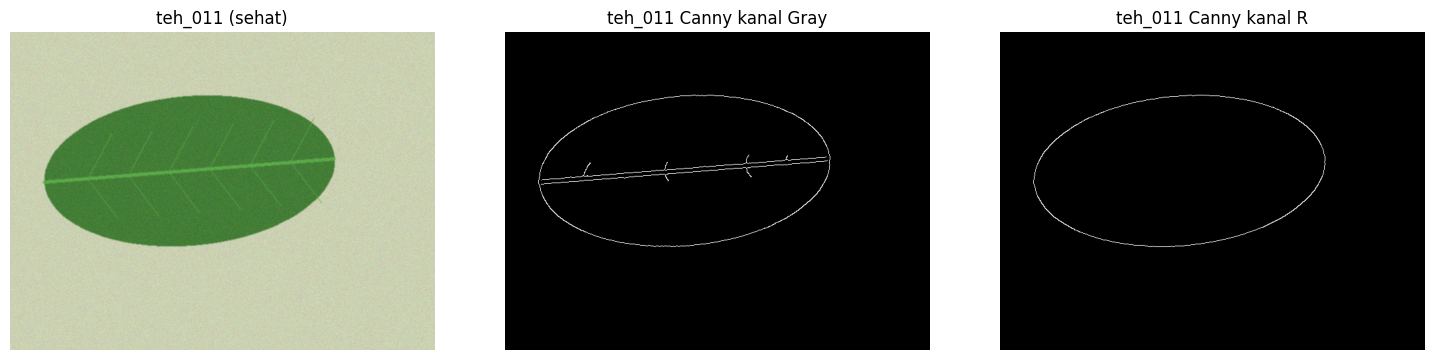

In [12]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0           # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R",
                     pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal",
                                     "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal",
                        values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul,
       ukuran=(15, 3.6))
